# Day 1: Wine Quality Dataset Inspection & Class Distribution Analysis
**Project:** Wine Quality Prediction (UCI Machine Learning Repository)
**Date:** October 5, 2026
**Tech Stack:** Python, pandas, numpy, seaborn, matplotlib, scikit-learn

## Objectives for Day 1
1. Load the physicochemical red wine dataset from the `Data/` directory.
2. Inspect structural attributes: shape, column data types, missing values, duplicates, and descriptive statistics.
3. Evaluate the distribution of target `quality` scores (scale 3–8).
4. Formulate initial insights regarding class imbalance and its implications on classification modeling.

In [1]:
import os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Style configuration
sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 120

print('Libraries successfully imported!')

Libraries successfully imported!


## 1. Load the Wine Quality Dataset
The UCI Wine Quality dataset uses semicolon (`;`) separators and records 11 physicochemical features along with the sensory `quality` rating.

In [2]:
# Load red wine data
DATA_PATH = Path('../Data/winequality-red.csv')
if not DATA_PATH.exists():
    DATA_PATH = Path('Data/winequality-red.csv')

df = pd.read_csv(DATA_PATH, sep=';')
print(f'Dataset Dimensions: {df.shape[0]} rows, {df.shape[1]} columns')
df.head()

Dataset Dimensions: 1599 rows, 12 columns


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


## 2. Dataset Structure & Integrity Inspection
Let's review column types, verify if missing values exist, and check for duplicate observations.

In [3]:
# Column info and data types
print('--- Dataset Info ---')
df.info()

print('\n--- Missing Value Check ---')
missing_counts = df.isnull().sum()
print(missing_counts[missing_counts > 0] if (missing_counts > 0).any() else 'No missing values found across all 12 columns.')

print('\n--- Duplicates Check ---')
dup_count = df.duplicated().sum()
print(f'Duplicate rows detected: {dup_count} ({dup_count / len(df) * 100:.2f}%)')

--- Dataset Info ---
<class 'pandas.DataFrame'>
RangeIndex: 1599 entries, 0 to 1598
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1599 non-null   float64
 1   volatile acidity      1599 non-null   float64
 2   citric acid           1599 non-null   float64
 3   residual sugar        1599 non-null   float64
 4   chlorides             1599 non-null   float64
 5   free sulfur dioxide   1599 non-null   float64
 6   total sulfur dioxide  1599 non-null   float64
 7   density               1599 non-null   float64
 8   pH                    1599 non-null   float64
 9   sulphates             1599 non-null   float64
 10  alcohol               1599 non-null   float64
 11  quality               1599 non-null   int64  
dtypes: float64(11), int64(1)
memory usage: 150.0 KB

--- Missing Value Check ---
No missing values found across all 12 columns.

--- Duplicates Check ---
Duplicate rows

## 3. Summary Statistics
Examining distribution ranges across physicochemical properties (min, quartiles, max, mean, and standard deviation).

In [4]:
# Summary statistics
summary_stats = df.describe().T
summary_stats['IQR'] = summary_stats['75%'] - summary_stats['25%']
summary_stats[['mean', 'std', 'min', '25%', '50%', '75%', 'max', 'IQR']].round(3)

,mean,std,min,25%,50%,75%,max,IQR
fixed acidity,8.320,1.741,4.600,7.100,7.900,9.200,15.900,2.100
volatile acidity,0.528,0.179,0.120,0.390,0.520,0.640,1.580,0.250
citric acid,0.271,0.195,0.000,0.090,0.260,0.420,1.000,0.330
residual sugar,2.539,1.410,0.900,1.900,2.200,2.600,15.500,0.700
chlorides,0.087,0.047,0.012,0.070,0.079,0.090,0.611,0.020
free sulfur dioxide,15.875,10.460,1.000,7.000,14.000,21.000,72.000,14.000
total sulfur dioxide,46.468,32.895,6.000,22.000,38.000,62.000,289.000,40.000
density,0.997,0.002,0.990,0.996,0.997,0.998,1.004,0.002
pH,3.311,0.154,2.740,3.210,3.310,3.400,4.010,0.190
sulphates,0.658,0.170,0.330,0.550,0.620,0.730,2.000,0.180


## 4. Target Variable Analysis: Quality Score Distribution
The target variable `quality` represents sensory evaluation scores given by wine experts.

In [5]:
# Compute frequency and percentages
quality_counts = df['quality'].value_counts().sort_index()
quality_pct = (quality_counts / len(df) * 100).round(2)

dist_table = pd.DataFrame({
    'Quality Score': quality_counts.index,
    'Sample Count': quality_counts.values,
    'Percentage (%)': quality_pct.values,
    'Cumulative (%)': quality_pct.cumsum().round(2).values
})
dist_table

,Quality Score,Sample Count,Percentage (%),Cumulative (%)
0,3,10,0.63,0.63
1,4,53,3.31,3.94
2,5,681,42.59,46.53
3,6,638,39.90,86.43
4,7,199,12.45,98.88
5,8,18,1.13,100.01


### 4.1 Visualizing Quality Class Frequencies
Let's plot a clean bar chart with count and percentage annotations to clearly visualize the concentration of scores.

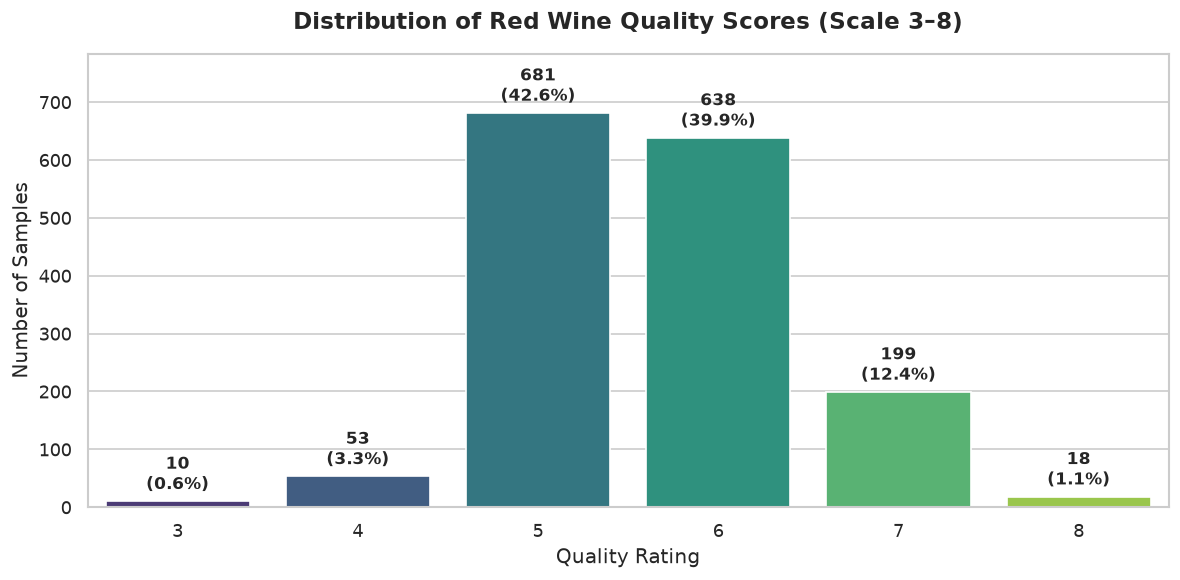

In [6]:
plt.figure(figsize=(10, 5))
palette = sns.color_palette('viridis', n_colors=len(quality_counts))
ax = sns.barplot(x=quality_counts.index, y=quality_counts.values, hue=quality_counts.index, palette=palette, legend=False)

plt.title('Distribution of Red Wine Quality Scores (Scale 3–8)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Quality Rating', fontsize=12)
plt.ylabel('Number of Samples', fontsize=12)
plt.ylim(0, max(quality_counts.values) * 1.15)

# Annotations
for p, count in zip(ax.patches, quality_counts.values):
    pct = f'{(count / len(df)) * 100:.1f}%'
    ax.annotate(f'{count}\n({pct})',
                (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='bottom', fontsize=10, xytext=(0, 4),
                textcoords='offset points', fontweight='bold')

plt.tight_layout()
# Ensure output directory exists
os.makedirs('../reports/figures', exist_ok=True)
plt.savefig('../reports/figures/day1_quality_distribution.png', dpi=300)
plt.show()

## 5. Day 1 Key Findings & Class Imbalance Analysis

### Observations:
1. **Severe Imbalance in Middle Classes:**
   - Quality scores **5** (42.59%) and **6** (39.90%) constitute **82.49%** of the entire dataset (1,319 out of 1,599 samples).
   - Borderline/extreme quality wines are rare:
     - Score 3: Only 10 samples (0.63%)
     - Score 4: Only 53 samples (3.31%)
     - Score 7: 199 samples (12.45%)
     - Score 8: Only 18 samples (1.13%)

2. **Implications for Machine Learning Modeling:**
   - **Accuracy Paradox:** A simple majority-class baseline model predicting only 5 or 6 would achieve over 82% nominal accuracy while having 0% recall on exceptional (score 8) or poor (score 3) wines.
   - **Stratification Necessity:** Random train-test splitting without stratification risks leaving minority classes with virtually 0 samples in the test or train splits. `StratifiedKFold` and stratified `train_test_split` are mandatory.
   - **Motivation for Target Binning (Day 3):** Grouping into binary (`good`: $\ge 7$ vs `bad`: $< 7$) or 3-tier (`low`, `medium`, `high`) creates more balanced, practically actionable classification boundaries.

### Next Steps (Day 2 - October 6, 2026):
- Conduct detailed Exploratory Data Analysis (EDA) on all 11 physicochemical features.
- Generate distribution plots (histograms, KDE, boxplots) and correlation heatmaps.